<a href="https://colab.research.google.com/github/thebluepetal8-cmd/Accessible-NeuroAI-Baseline/blob/main/SHAP_summary_pynb.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Dataset loaded: 5875 voice recordings across 42 unique patients.
Training patients: 33 | Testing patients: 9

--- Baseline Evaluation (Patient-Separated Test Set) ---
Mean Absolute Error (MAE): 10.70 UPDRS points
R² Score: -1.18

Generating SHAP feature importance plot...


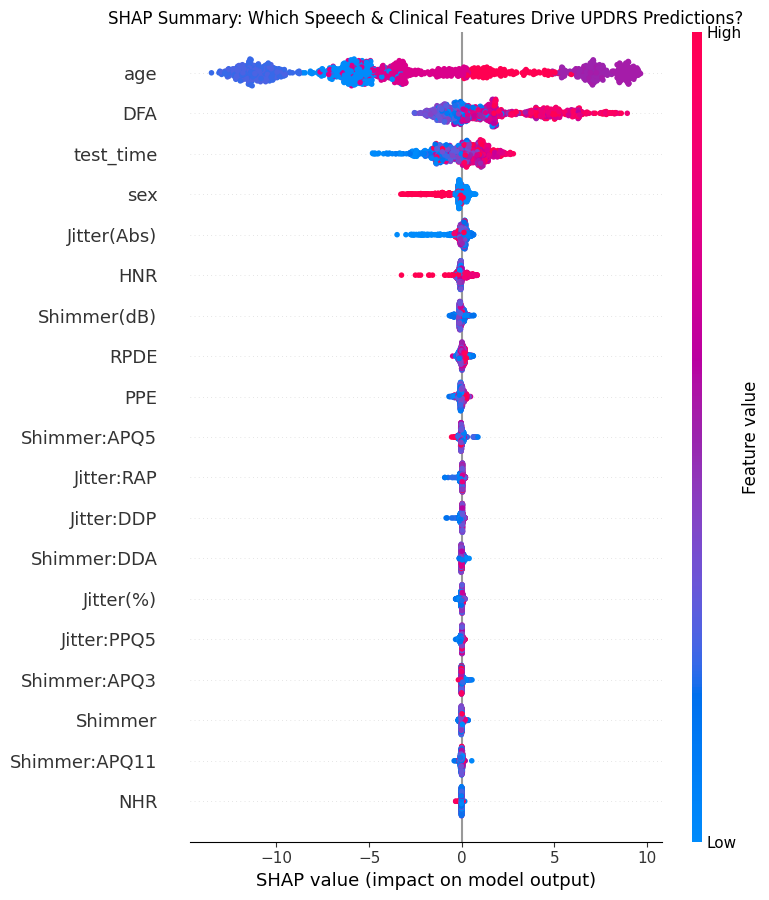

In [1]:
# 1. Install required libraries (Google Colab runs this automatically)
!pip install -q ucimlrepo shap scikit-learn pandas matplotlib

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from ucimlrepo import fetch_ucirepo
from sklearn.model_selection import GroupShuffleSplit
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score
import shap

# 2. Load the UCI Parkinson's Telemonitoring Dataset (ID: 189)
print("Downloading UCI Parkinson's Telemonitoring dataset...")
parkinsons = fetch_ucirepo(id=189)

X = parkinsons.data.features
y = parkinsons.data.targets['total_UPDRS']  # Disease progression score
subject_ids = parkinsons.data.ids['subject#']  # Patient IDs

print(f"Dataset loaded: {X.shape[0]} voice recordings across {subject_ids.nunique()} unique patients.")

# 3. Patient-Level Train/Test Split (Prevents Data Leakage - Section 10.2 of your paper!)
# Using GroupShuffleSplit ensures recordings from the same patient never appear in both train and test sets.
gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
train_idx, test_idx = next(gss.split(X, y, groups=subject_ids))

X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

print(f"Training patients: {subject_ids.iloc[train_idx].nunique()} | Testing patients: {subject_ids.iloc[test_idx].nunique()}")

# 4. Train an Interpretable Baseline Model (Section 10.3 of your paper)
model = RandomForestRegressor(n_estimators=100, random_state=42)
model.fit(X_train, y_train)

# 5. Evaluate Baseline Performance
predictions = model.predict(X_test)
mae = mean_absolute_error(y_test, predictions)
r2 = r2_score(y_test, predictions)

print("\n--- Baseline Evaluation (Patient-Separated Test Set) ---")
print(f"Mean Absolute Error (MAE): {mae:.2f} UPDRS points")
print(f"R² Score: {r2:.2f}")

# 6. Explainable AI using SHAP (Section 11 of your paper)
print("\nGenerating SHAP feature importance plot...")
explainer = shap.TreeExplainer(model)
shap_values = explainer.shap_values(X_test)

plt.figure(figsize=(10, 6))
shap.summary_plot(shap_values, X_test, show=False)
plt.title("SHAP Summary: Which Speech & Clinical Features Drive UPDRS Predictions?")
plt.tight_layout()
plt.show()
